<div dir="rtl" style="text-align: right;">


# چالش آماری علم داده، ترم ۳ (شماره ۱)
---

| مورد | توضیح |
|---|---|
| نام | Kiarash Akbari |
| مجموعه | آزمایشگاه فناوری‌های مالی داتین |
| تاریخ | ۱۵ مهر ۱۴۰۵ (1405-07-15) |
| فایل داده | `bank_midterm.csv` (۴۰۰ مشتری کارت بانکی) |
| متغیر پاسخ | `monthly_spend` (رگرسیون خطی) و `default` (رگرسیون لجستیک) |

---
## مرحله‌ی اول: بررسی و آماده‌سازی داده



### هدف این بخش
قبل از برازش مدل، داده را بررسی می‌کنم و فقط چیزهایی را اصلاح می‌کنم که واقعاً خطا هستند. در پایان هم توضیح می‌دهم چرا بعضی چیزها را عمداً دست نزدم.

</div>


<div dir="rtl" style="text-align: right;">

### ۱. تنظیمات اولیه


</div>

In [ ]:
import os
from pathlib import Path
import numpy as np
import pandas as pd

pd.set_option('display.width', 120)
pd.set_option('display.max_columns', 20)
np.random.seed(42)

def find_repo_root(start=None):
    p = Path(start or os.getcwd()).resolve()
    for folder in [p, *p.parents]:
        if (folder / '.git').exists():
            return folder
    raise FileNotFoundError(f'.git not found above {p}')

REPO_ROOT = find_repo_root()
DATA_PATH = REPO_ROOT / 'term-3' / 'datasets' / 'bank_midterm.csv'
if not DATA_PATH.exists():
    raise FileNotFoundError(f'dataset not found: {DATA_PATH}')

OUT_DIR = Path('data')
OUT_DIR.mkdir(exist_ok=True)
print(f'repo root: {REPO_ROOT}')
print(f'data file: {DATA_PATH}')

repo root: /home/rash/Code/PROJECTS/dotin
data file: /home/rash/Code/PROJECTS/dotin/term-3/datasets/bank_midterm.csv


<div dir="rtl" style="text-align: right;">



## ۲. خواندن داده و نگاه کلی
</div>

In [ ]:
raw = pd.read_csv(DATA_PATH)
df = raw.copy()

print(f'shape: {df.shape[0]} rows, {df.shape[1]} columns')
df.head()

shape: 400 rows, 14 columns


,id,age,income,tenure_months,n_products,savings,investments,total_assets,region,debt_ratio,late_payments,legal_case,monthly_spend,default
0,1,41,34.5,22,5,216.7,22.6,239.3,Tehran,0.179,1,1,7.77,1
1,2,59,26.2,30,6,158.4,36.4,194.8,Tehran,0.323,2,0,6.44,0
2,3,56,17.5,60,2,107.9,22.2,130.1,Metro,0.327,1,0,3.97,0
3,4,58,17.4,102,3,104.2,34.4,138.6,Other,0.422,0,0,1.48,0
4,5,64,27.2,35,1,180.4,20.4,200.8,Tehran,0.661,0,0,4.17,0


In [ ]:
summary = pd.DataFrame({
    'dtype': df.dtypes.astype(str),
    'missing': df.isna().sum(),
    'unique': df.nunique(),
})
summary

,dtype,missing,unique
id,int64,0,400
age,int64,0,44
income,float64,0,271
tenure_months,int64,0,109
n_products,int64,0,8
savings,float64,0,378
investments,float64,0,341
total_assets,float64,0,376
region,str,0,3
debt_ratio,float64,0,288


<div dir="rtl" style="text-align: right;">

## ۳. چک‌های کیفیت داده
</div>

In [ ]:
checks = {
    'missing values (total)': int(df.isna().sum().sum()),
    'duplicate rows (without id)': int(df.drop(columns='id').duplicated().sum()),
    'id is unique': bool(df['id'].is_unique),
    'income <= 0': int((df['income'] <= 0).sum()),
    'monthly_spend <= 0': int((df['monthly_spend'] <= 0).sum()),
    'tenure_months <= 0': int((df['tenure_months'] <= 0).sum()),
    'debt_ratio outside [0, 1]': int((~df['debt_ratio'].between(0, 1)).sum()),
    'age outside [18, 100]': int((~df['age'].between(18, 100)).sum()),
    'late_payments outside [0, 12]': int((~df['late_payments'].between(0, 12)).sum()),
    'legal_case not in {0,1}': int((~df['legal_case'].isin([0, 1])).sum()),
    'default not in {0,1}': int((~df['default'].isin([0, 1])).sum()),
}
pd.Series(checks, name='result').to_frame()

,result
missing values (total),0
duplicate rows (without id),0
id is unique,True
income <= 0,0
monthly_spend <= 0,0
tenure_months <= 0,0
"debt_ratio outside [0, 1]",0
"age outside [18, 100]",0
"late_payments outside [0, 12]",0
"legal_case not in {0,1}",0


In [ ]:
print(df['region'].value_counts(dropna=False))
print()
print('labels with extra spaces:', int((df['region'] != df['region'].str.strip()).sum()))

region
Tehran    162
Other     121
Metro     117
Name: count, dtype: int64

labels with extra spaces: 0


<div dir="rtl" style="text-align: right;">

**نتیجه:** مقدار گمشده، سطر تکراری، مقدار غیرمنطقی و برچسب اشتباه در `region` وجود ندارد. داده از نظر ظاهری تمیز است. حالا دو چیز را بررسی می‌کنم که ممکن است مشکل ساز باشند ولی خطای ورود داده نیستند.

</div>

<div dir="rtl" style="text-align: right;">

## ۴. رابطه‌ی بین ستون‌های مالی
</div>

In [ ]:
gap = (df['total_assets'] - df['savings'] - df['investments']).round(2)
print('max |total_assets - savings - investments|:', gap.abs().max())
print('rows where the identity breaks:', int((gap.abs() > 0.05).sum()))

print()
print('corr(income, savings):', round(df['income'].corr(df['savings']), 4))
print('savings / income  ->  mean:', round((df['savings'] / df['income']).mean(), 2),
      ' std:', round((df['savings'] / df['income']).std(), 2))

max |total_assets - savings - investments|: 0.0
rows where the identity breaks: 0

corr(income, savings): 0.9952
savings / income  ->  mean: 5.98  std: 0.41


<div dir="rtl" style="text-align: right;">

**نتیجه:**
- `total_assets` در هر ۴۰۰ سطر دقیقاً برابر `savings + investments` است. یعنی این ستون اطلاعات تازه‌ای ندارد.
- `savings` و `income` تقریباً یک رابطه‌ی خطی کامل دارند. این یعنی همخطی شدید.

این دو مورد خطای داده نیستند، ولی روی مدل رگرسیون اثر مستقیم دارند. در سوال ۱ باید با رتبه‌ی ماتریس طرح و VIF نشانشان بدهم، پس الان حذفشان نمی‌کنم.

</div>

<div dir="rtl" style="text-align: right;">

## ۵. مقدارهای دور از بقیه (پرت)
</div>

In [ ]:
num_cols = ['income', 'savings', 'investments', 'tenure_months', 'monthly_spend']
rows = []
for c in num_cols:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    far = df[(df[c] > q3 + 3 * iqr) | (df[c] < q1 - 3 * iqr)]
    rows.append({'column': c, 'n_far_values': len(far), 'max': df[c].max(), 'median': df[c].median()})
pd.DataFrame(rows)

,column,n_far_values,max,median
0,income,7,190.00,31.500
1,savings,7,1122.30,189.750
2,investments,8,332.50,43.850
3,tenure_months,0,128.00,35.000
4,monthly_spend,17,57.88,4.845


In [ ]:
cols = ['id', 'income', 'savings', 'investments', 'monthly_spend']
df.nlargest(5, 'income')[cols]

,id,income,savings,investments,monthly_spend
310,311,190.0,1122.3,15.3,3.50
367,368,170.0,1002.1,47.8,2.50
31,32,160.0,958.9,7.5,39.45
151,152,150.0,917.5,85.7,3.00
83,84,109.0,658.7,110.4,57.88


In [ ]:
df.nlargest(5, 'monthly_spend')[cols + ['region']]

,id,income,savings,investments,monthly_spend,region
83,84,109.0,658.7,110.4,57.88,Tehran
99,100,97.4,581.4,52.2,55.82,Tehran
355,356,25.1,142.8,63.5,45.00,Tehran
365,366,82.9,485.2,131.9,42.09,Tehran
397,398,58.9,360.1,57.4,40.72,Tehran


<div dir="rtl" style="text-align: right;">

**نتیجه:** چند مشتری درآمد و پس‌انداز خیلی بالا دارند و چند نفر هم خرج ماهانه‌ی خیلی بالا. این مقدارها ممکن و منطقی‌اند، یعنی نمی‌شود گفت اشتباه ثبت شده‌اند. فقط از بقیه‌ی داده دور هستند.

</div>

<div dir="rtl" style="text-align: right;">

## ۶. تغییرهای واقعی روی داده
</div>

In [ ]:
df['region'] = pd.Categorical(df['region'], categories=['Tehran', 'Metro', 'Other'])

for c in ['n_products', 'late_payments', 'legal_case', 'default']:
    df[c] = df[c].astype(int)

print(df['region'].cat.categories.tolist())
print('rows before:', len(raw), ' rows after:', len(df))

['Tehran', 'Metro', 'Other']
rows before: 400  rows after: 400


In [ ]:
df.to_csv(os.path.join(OUT_DIR, 'bank_clean.csv'), index=False)
print('saved: data/bank_clean.csv')

saved: data/bank_clean.csv


<div dir="rtl" style="text-align: right;">

## ۷. چرا بیشتر از این پولیش نکردم

**کاری که کردم:**
- `region` را به متغیر دسته‌ای تبدیل کردم و Tehran را سطح مرجع گذاشتم. بدون این کار، مدل ترتیب الفبایی را مرجع می‌گیرد و تفسیر ضریب‌ها سخت‌تر می‌شود.
- نوع ستون‌های شمارشی و ۰/۱ را عدد صحیح نگه داشتم.
- هیچ سطری حذف نشد (۴۰۰ سطر قبل و بعد).

**کارهایی که عمدا نکردم:**

۱. **حذف `total_assets` یا `savings`.** سوال ۱ از من می‌خواهد مدل را روی داده‌ی خام برازش بدهم و علت مشکل را با رتبه‌ی ماتریس و مقادیر ویژه نشان بدهم. اگر قبل از آن ستون را بردارم، چیزی برای نشان دادن نمی‌ماند.

۲. **حذف مقدارهای دور از بقیه.** سوال ۱ می‌خواهد مشاهدات تأثیرگذار را با اهرم، Cook's D و DFFITS تشخیص بدهم و بعد مدل را بدون آن‌ها برازش بدهم. اگر الان حذفشان کنم، این تشخیص بی‌معنی می‌شود. از طرف دیگر، دلیلی ندارد که این مقدارها اشتباه باشند، پس حذف بدون تشخیص درست نیست.

۳. **پر کردن یا تغییر مقدارها.** مقدار گمشده نداریم و هیچ مقداری خارج از محدوده‌ی منطقی نبود. هر تغییری فقط داده را از واقعیت دور می‌کرد.

۴. **تبدیل لگاریتمی یا استانداردسازی.** در سوال ۲ تبدیل مناسب را باید با Box–Cox و فاصله‌ی اطمینان انتخاب کنم. تبدیل زودهنگام جواب را از قبل تعیین می‌کند.

**خلاصه:** داده از نظر ورود اطلاعات تمیز است. مشکل‌هایش آماری‌اند (همخطی و نقاط تأثیرگذار) و خود سوال‌ها از من می‌خواهند آن‌ها را تشخیص بدهم و درست کنم. پس در این مرحله فقط داده را آماده می‌کنم و تشخیص و اصلاح را به بخش‌های بعدی می‌سپارم.

</div>

<div dir="rtl" style="text-align: right;">

## ۸. تحلیل اکتشافی (EDA)

هدف این بخش فقط شناخت داده است. هیچ تغییری روی داده نمی‌دهم و چیزی را حذف نمی‌کنم. چیزهایی که اینجا می‌بینم بعداً در سوال ۱ و ۲ به کار می‌آیند: چولگی (برای Box–Cox)، همخطی (برای VIF) و تغییر پراکندگی (برای ناهمسانی واریانس).

</div>

In [1]:
import seaborn as sns
import matplotlib.pyplot as plt

sns.set(style='whitegrid')
plt.rcParams['figure.dpi'] = 110

<div dir="rtl" style="text-align: right;">

### الف) توزیع پاسخ و درآمد

</div>

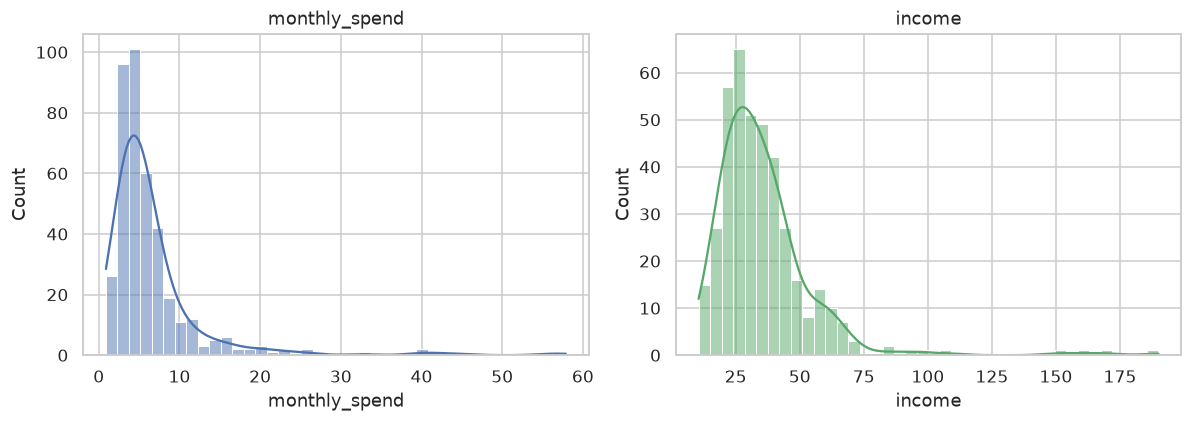

skewness:
monthly_spend    4.42
income           3.58
dtype: float64

skewness after log:
monthly_spend    0.88
income           0.51
dtype: float64


In [2]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df['monthly_spend'], bins=40, kde=True, ax=axes[0], color='#4C72B0')
axes[0].set_title('monthly_spend')
sns.histplot(df['income'], bins=40, kde=True, ax=axes[1], color='#55A868')
axes[1].set_title('income')
plt.tight_layout()
plt.show()

print('skewness:')
print(df[['monthly_spend', 'income']].skew().round(2))
print()
print('skewness after log:')
print(np.log(df[['monthly_spend', 'income']]).skew().round(2))

<div dir="rtl" style="text-align: right;">

**توضیح:** هر دو توزیع به راست کشیده شده‌اند. چولگی `monthly_spend` برابر ۴٫۴۲ و `income` برابر ۳٫۵۸ است. بیشتر مشتری‌ها خرج کم دارند و چند نفر خیلی بالا هستند. بعد از لگاریتم چولگی کمتر می‌شود (۰٫۸۸ و ۰٫۵۱). این نشان می‌دهد در سوال ۲ تبدیل Box–Cox احتمالاً لازم می‌شود. فعلاً فقط یادداشتش می‌کنم و تبدیلی انجام نمی‌دهم.

</div>

<div dir="rtl" style="text-align: right;">

### ب) درآمد و پس‌انداز (همخطی)

</div>

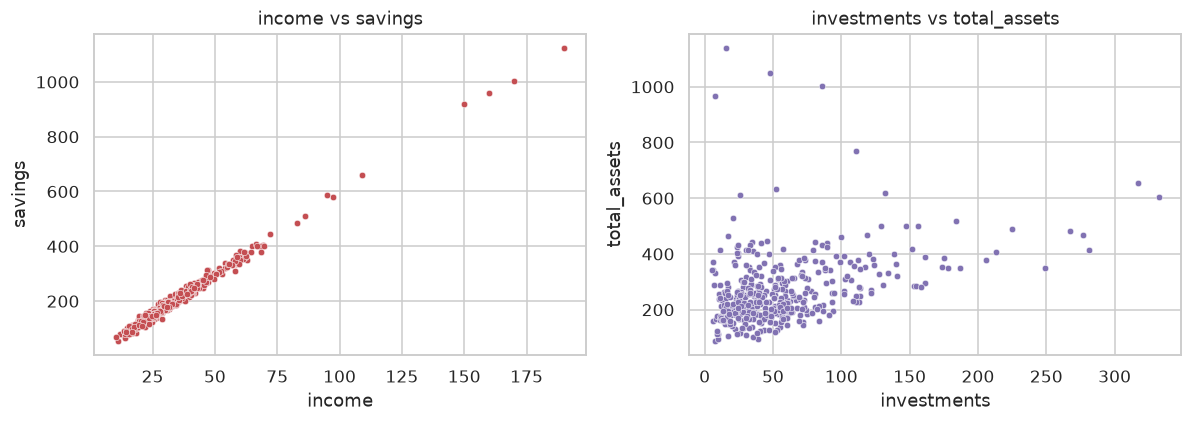

corr(income, savings): 0.9952
corr(investments, total_assets): 0.3768


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x='income', y='savings', ax=axes[0], s=18, color='#C44E52')
axes[0].set_title('income vs savings')
sns.scatterplot(data=df, x='investments', y='total_assets', ax=axes[1], s=18, color='#8172B2')
axes[1].set_title('investments vs total_assets')
plt.tight_layout()
plt.show()

print('corr(income, savings):', round(df['income'].corr(df['savings']), 4))
print('corr(investments, total_assets):', round(df['investments'].corr(df['total_assets']), 4))

<div dir="rtl" style="text-align: right;">

**توضیح:** نمودار سمت چپ تقریباً یک خط راست است (همبستگی ۰٫۹۹۵۲). یعنی `savings` تقریباً مضرب ثابتی از `income` است. نمودار سمت راست پراکنده است، چون `total_assets` از جمع `savings` و `investments` ساخته شده و به تنهایی با `investments` رابطه‌ی ضعیف‌تری دارد (۰٫۳۷۶۸). این رابطه‌ی ساختگی بعداً در سوال ۱-الف مشکل رتبه‌ی ماتریس طرح را می‌سازد.

</div>

<div dir="rtl" style="text-align: right;">

### ج) خرج ماهانه در برابر درآمد، به تفکیک منطقه

</div>

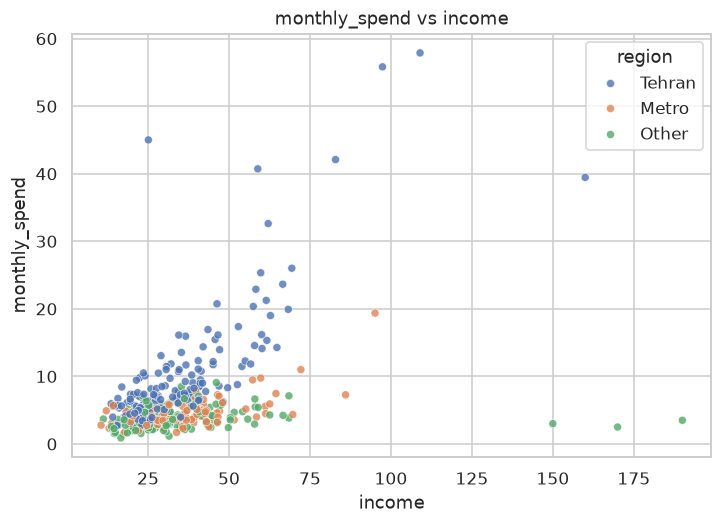

,count,median,mean,std
region,,,,
Tehran,162,7.17,10.10,8.93
Metro,117,4.12,4.54,2.08
Other,121,3.50,3.78,1.61


In [4]:
plt.figure(figsize=(7.5, 5))
sns.scatterplot(data=df, x='income', y='monthly_spend', hue='region', s=28, alpha=0.8)
plt.title('monthly_spend vs income')
plt.show()

df.groupby('region', observed=True)['monthly_spend'].agg(['count', 'median', 'mean', 'std']).round(2)

<div dir="rtl" style="text-align: right;">

**توضیح:** رابطه‌ی خرج و درآمد مثبت است ولی پراکندگی با بالا رفتن درآمد زیاد می‌شود (شکل شبیه قیف). بیشتر نقاط پرخرج مربوط به تهران هستند. میانه‌ی خرج در تهران ۷٫۱۷ است، در Metro برابر ۴٫۱۲ و در Other برابر ۳٫۵۰. انحراف معیار تهران (۸٫۹۳) چند برابر دو منطقه‌ی دیگر است. این الگو نشانه‌ی احتمالی ناهمسانی واریانس است و در سوال ۲-الف باید با آزمون Breusch–Pagan بررسی شود.

</div>

<div dir="rtl" style="text-align: right;">

### د) خرج ماهانه در هر منطقه

</div>

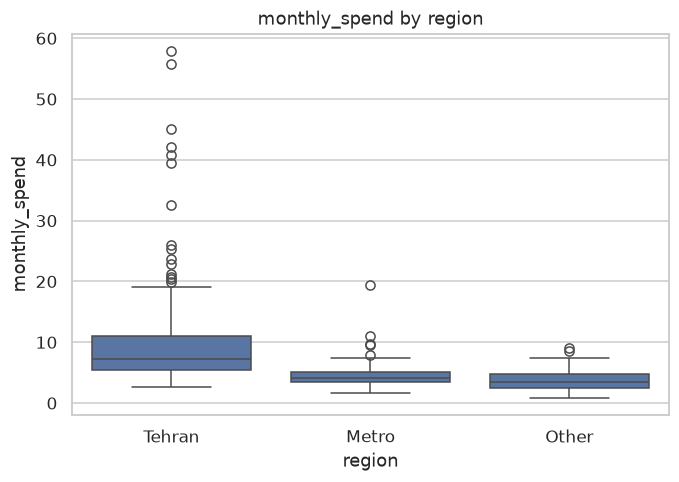

In [5]:
plt.figure(figsize=(7, 4.5))
sns.boxplot(data=df, x='region', y='monthly_spend', order=['Tehran', 'Metro', 'Other'])
plt.title('monthly_spend by region')
plt.show()

<div dir="rtl" style="text-align: right;">

**توضیح:** جعبه‌ی تهران هم بالاتر است و هم بازتر. ۵ مقدار بالای خرج (تا ۵۷٫۸۸) همگی مربوط به تهران‌اند. این یعنی `region` باید در مدل باشد، همان‌طور که سوال خواسته است.

</div>

<div dir="rtl" style="text-align: right;">

### ه) ماتریس همبستگی

</div>

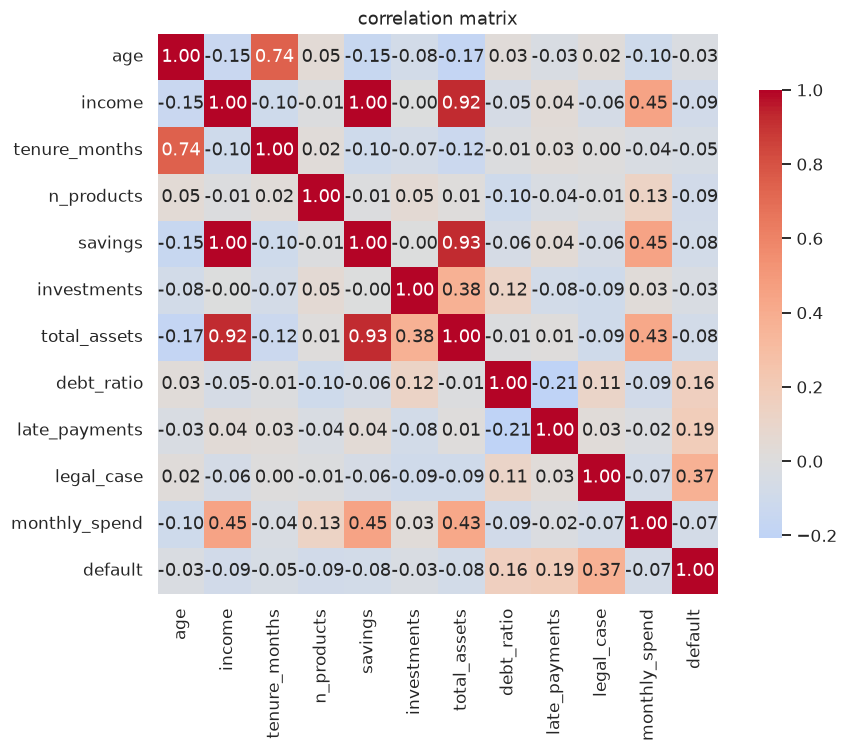

income           0.45
savings          0.45
total_assets     0.43
n_products       0.13
investments      0.03
late_payments   -0.02
tenure_months   -0.04
default         -0.07
legal_case      -0.07
debt_ratio      -0.09
age             -0.10
Name: monthly_spend, dtype: float64


In [6]:
num = df.select_dtypes('number').drop(columns='id')
corr = num.corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0, square=True, cbar_kws={'shrink': 0.8})
plt.title('correlation matrix')
plt.tight_layout()
plt.show()

print(corr['monthly_spend'].drop('monthly_spend').sort_values(ascending=False).round(2))

<div dir="rtl" style="text-align: right;">

**توضیح:** قوی‌ترین همبستگی با `monthly_spend` مربوط به `income` و `savings` (هر دو ۰٫۴۵) و `total_assets` (۰٫۴۳) است. این سه خودشان به هم وابسته‌اند، پس اطلاعات مستقل زیادی نمی‌دهند. بقیه‌ی متغیرها (مثل `age` و `tenure_months`) همبستگی خطی ضعیفی دارند. همبستگی ضعیف یعنی رابطه‌ی خطی ضعیف است و نه این‌که اثری ندارند.

</div>

<div dir="rtl" style="text-align: right;">

### خلاصه‌ی بخش EDA

- `monthly_spend` و `income` چولگی راست زیادی دارند (احتمال نیاز به تبدیل در سوال ۲).
- `income` و `savings` تقریباً یکی هستند و `total_assets` مجموع `savings` و `investments` است (همخطی در سوال ۱).
- پراکندگی خرج با درآمد زیاد می‌شود و تهران بیشترین پراکندگی را دارد (ناهمسانی واریانس در سوال ۲).
- در این مرحله هیچ داده‌ای حذف یا تغییر نکرد.

</div>

<div dir="rtl" style="text-align: right;">

## ۹. سوال ۱-الف: مدل خام و همخطی کامل

مدل سوال را روی داده‌ی خام برازش می‌دهم، بدون هیچ حذف یا تغییری:

`monthly_spend ~ age + income + tenure_months + n_products + savings + investments + total_assets + region`

ماتریس طرح X شامل عرض از مبدأ، ۷ متغیر عددی و ۲ ستون dummy برای `region` است. پس ۱۰ ستون دارد. اگر همه‌ی ستون‌ها مستقل باشند، رتبه ۱۰ می‌شود.

</div>

In [ ]:
import statsmodels.formula.api as smf

formula_raw = ('monthly_spend ~ age + income + tenure_months + n_products '
               '+ savings + investments + total_assets + C(region)')
m_raw = smf.ols(formula_raw, data=df).fit()

X = m_raw.model.exog
names = m_raw.model.exog_names
n, p = X.shape

print(f'n = {n}, p (columns of X) = {p}')
print(f'rank(X) = {np.linalg.matrix_rank(X)}')

n = 400, p (columns of X) = 10
rank(X) = 9


/tmp/ipykernel_51081/3015295052.py:5: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  m_raw = smf.ols(formula_raw, data=df).fit()


<div dir="rtl" style="text-align: right;">

**توضیح:** ماتریس طرح ۱۰ ستون دارد ولی رتبه‌اش فقط ۹ است. یعنی یک ستون ترکیب خطی بقیه است و `X'X` معکوس‌پذیر نیست. با این حال نرم‌افزار خطا نمی‌دهد و عدد می‌دهد. در ادامه می‌بینیم این عددها قابل اعتماد نیستند.

</div>

In [ ]:
eigvals, eigvecs = np.linalg.eigh(X.T @ X)

print('eigenvalues of X\'X (smallest 4):')
print(eigvals[:4])
print()
print('largest eigenvalue:', f'{eigvals[-1]:.3e}')
print('condition number of X:', f'{np.linalg.cond(X):.3e}')
print()
print('eigenvector of the smallest eigenvalue:')
print(pd.Series(eigvecs[:, 0], index=names).round(3))

eigenvalues of X'X (smallest 4):
[-1.28451916e-09  1.27895655e+01  5.19900241e+01  1.16607526e+02]

largest eigenvalue: 6.183e+07
condition number of X: 7.964e+15

eigenvector of the smallest eigenvalue:
Intercept             0.000
C(region)[T.Metro]   -0.000
C(region)[T.Other]   -0.000
age                  -0.000
income                0.000
tenure_months         0.000
n_products           -0.000
savings              -0.577
investments          -0.577
total_assets          0.577
dtype: float64


<div dir="rtl" style="text-align: right;">

**توضیح:** کوچک‌ترین مقدار ویژه‌ی `X'X` عملاً صفر است (حدود ۱e-9 و حتی منفی، که فقط خطای گرد کردن کامپیوتر است). عدد شرط ماتریس حدود ۵٫۴e15 است. بردار ویژه‌ی متناظر فقط روی سه ستون مقدار دارد: `savings` و `investments` با وزن ‎−۰٫۵۷۷ و `total_assets` با وزن ‎+۰٫۵۷۷، و بقیه صفرند. یعنی رابطه‌ی خطی دقیق این است:

`total_assets − savings − investments = 0`

این همان چیزی است که در بخش ۴ دیدیم: `total_assets` همیشه برابر جمع دو ستون دیگر است.

</div>

In [ ]:
pd.DataFrame({'coef': m_raw.params, 'se': m_raw.bse}).round(4)

,coef,se
Intercept,4.6857,1.3661
C(region)[T.Metro],-5.5405,0.6027
C(region)[T.Other],-6.6684,0.5971
age,-0.0734,0.0300
income,0.1777,0.1283
tenure_months,0.0256,0.0127
n_products,0.5916,0.1591
savings,-0.0049,0.0144
investments,0.0050,0.0079
total_assets,0.0001,0.0074


In [ ]:
v = eigvecs[:, 0] / eigvecs[:, 0][names.index('total_assets')]
beta_alt = m_raw.params.values + 5 * v
fitted_alt = X @ beta_alt

print('max |fitted_original - fitted_shifted|:', np.abs(m_raw.fittedvalues.values - fitted_alt).max())
print('coef of savings      -> original:', round(m_raw.params['savings'], 4),
      ' shifted:', round(beta_alt[names.index('savings')], 4))
print('coef of total_assets -> original:', round(m_raw.params['total_assets'], 4),
      ' shifted:', round(beta_alt[names.index('total_assets')], 4))

max |fitted_original - fitted_shifted|: 1.5972290157151292e-10
coef of savings      -> original: -0.0049  shifted: -5.0049
coef of total_assets -> original: 0.0001  shifted: 5.0001


<div dir="rtl" style="text-align: right;">

**توضیح:** وقتی یک جهت صفر در `X'X` داریم، می‌توان به ضرایب هر مقدار دلخواه از آن جهت را اضافه کرد و مقدارهای برازش‌شده کاملاً یکسان می‌مانند. اینجا ضرایب را جابه‌جا کردم و اختلاف مقدارهای برازش‌شده صفر (در حد خطای گرد کردن) شد، ولی ضریب `savings` و `total_assets` عوض شد. نتیجه: بی‌نهایت جواب برای ضرایب وجود دارد و فقط پیش‌بینی ثابت است.

عددهایی که نرم‌افزار چاپ می‌کند یکی از همین بی‌نهایت جواب است. `statsmodels` از شبه‌معکوس استفاده می‌کند و جواب با کوچک‌ترین نُرم را برمی‌گرداند. پس این ضرایب و خطاهای استاندارد را نمی‌شود تفسیر کرد.

</div>

<div dir="rtl" style="text-align: right;">

### اصلاح مدل

برای رفع همخطی کامل، `total_assets` را حذف می‌کنم. چون مقدار آن دقیقاً از `savings` و `investments` ساخته می‌شود، حذفش هیچ اطلاعاتی را از دست نمی‌دهد. هر کدام از سه ستون را می‌شد حذف کرد، ولی `total_assets` انتخاب طبیعی است چون ستون مشتق‌شده است.

در سوال ۱-ب می‌بینیم که `income` و `savings` هم تقریباً یکی هستند. برای همین مدل نهایی بعد از آن مرحله `savings` را هم از دست می‌دهد و همان مدل «بدون `total_assets` و `savings`» می‌شود که سوال ۲ از آن استفاده می‌کند.

</div>

In [ ]:
formula_fix = ('monthly_spend ~ age + income + tenure_months + n_products '
               '+ savings + investments + C(region)')
m_fix = smf.ols(formula_fix, data=df).fit()
X_fix = m_fix.model.exog

def summarize(model, X_mat):
    rank = np.linalg.matrix_rank(X_mat)
    return {
        'columns (p)': X_mat.shape[1],
        'rank(X)': rank,
        'nominal df = n - p': n - X_mat.shape[1],
        'true df = n - rank': n - rank,
        'smallest eigenvalue': f'{np.linalg.eigvalsh(X_mat.T @ X_mat)[0]:.2e}',
        'condition number': f'{np.linalg.cond(X_mat):.2e}',
        'RSS': round(model.ssr, 2),
        'R2': round(model.rsquared, 4),
    }

pd.DataFrame({
    'raw model': summarize(m_raw, X),
    'without total_assets': summarize(m_fix, X_fix),
})

,raw model,without total_assets
columns (p),10,9
rank(X),9,9
nominal df = n - p,390,391
true df = n - rank,391,391
smallest eigenvalue,-1.28e-09,1.28e+01
condition number,7.96e+15,1.44e+03
RSS,9555.01,9555.01
R2,0.4408,0.4408


In [ ]:
pd.DataFrame({'coef': m_fix.params, 'se': m_fix.bse}).round(4)

,coef,se
Intercept,4.6857,1.3661
C(region)[T.Metro],-5.5405,0.6027
C(region)[T.Other],-6.6684,0.5971
age,-0.0734,0.0300
income,0.1777,0.1283
tenure_months,0.0256,0.0127
n_products,0.5916,0.1591
savings,-0.0047,0.0215
investments,0.0051,0.0052


<div dir="rtl" style="text-align: right;">

### درجه‌ی آزادی باقی‌مانده قبل و بعد از اصلاح

- **قبل از اصلاح:** اگر ستون‌ها را بشماریم، `n − p = 400 − 10 = 390`. ولی رتبه‌ی واقعی ۹ است، پس درجه‌ی آزادی واقعی `n − rank = 391` است. نرم‌افزار هم ۳۹۱ گزارش می‌کند، چون بر اساس رتبه حساب می‌کند.
- **بعد از اصلاح:** `p = rank = 9` و `df = 400 − 9 = 391`.

درجه‌ی آزادی در هر دو حالت ۳۹۱ است. فرق در تفسیر است: قبل از اصلاح، ۱۰ پارامتر داریم ولی فقط ۹ پارامتر مستقل قابل برآورد است. بعد از اصلاح، هر ۹ پارامتر یکتا برآورد می‌شوند.

### چه چیزی عوض شد و چه چیزی نه

- RSS و R² یکسان‌اند. پس قدرت پیش‌بینی مدل با حذف `total_assets` کمتر نشد. این همان نتیجه‌ی بخش قبل است: فقط ضرایب نامعین بودند، نه برازش.
- ضریب‌های مدل خام (مثل `savings` و `total_assets`) بی‌معنی بودند. در مدل اصلاح‌شده یکتا هستند.
- عدد شرط به‌شدت کاهش پیدا کرد. هنوز `income` و `savings` همخطی شدید دارند و این در بخش بعد (VIF) بررسی می‌شود.

</div>